# K-means clustering on stock data

**Goal.** Group stock data into clusters ("market regimes") with **k-means**

Solve:
1. with **Nelder–Mead** (`scipy.optimize.minimize`), the derivative-free optimization method.
2. with the classical **Lloyd algorithm**.

**Data.** `stock_market_prices.xlsx`- simulated month-end prices of a market index and a stock, and the rolling volatility of the stock. Each month is a point in 3-D space.

**Steps**
1. Load the Excel data
2. Build features (compute returns and rolling volatility of simulated prices)
3. Standardize the features
4. Formulate the k-means optimization problem
5. Minimize it with Nelder–Mead
6. Local minima: multi-start
7. Lloyd's algorithm 
8. Choosing the number of clusters $k$ (elbow, silhouette)
9. Interpretation

## Step 0 – Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as so

np.set_printoptions(precision=4, suppress=True)
COLORS = ["#1F3864", "#C55A11", "#548235", "#7030A0", "#BF9000", "#2E75B6"]

## Step 1 – Load data


In [3]:
df = pd.read_excel("stock_market_prices.xlsx", sheet_name="Prices", parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df.head()

,Date,Market_Index,Stock_Price
0,2021-01-31,4000.00,150.00
1,2021-02-28,3914.68,149.95
2,2021-03-31,3915.22,153.25
3,2021-04-30,4239.66,174.94
4,2021-05-31,4399.33,184.76


## Step 2 – Features

Each observation $i$ is a vector $\mathbf x_i\in\mathbb R^3$:

| feature | definition | meaning |
|---|---|---|
| `Market_Return` | $\dfrac{P^{m}_t}{P^{m}_{t-1}}-1$ | how the market did this month |
| `Stock_Return` | $\dfrac{P^{s}_t}{P^{s}_{t-1}}-1$ | how the stock did this month |
| `Stock_Vol3M` | standard deviation of the last 3 monthly stock returns | recent risk level (a standard "regime" indicator) |


In [4]:
df["Market_Return"] = df["Market_Index"].pct_change()
df["Stock_Return"]  = df["Stock_Price"].pct_change()
df["Stock_Vol3M"]   = df["Stock_Return"].rolling(window=3).std()
#The first rows have no previous price (return) or fewer than 3 returns (volatility), so they are dropped.
df = df.dropna().reset_index(drop=True)

features = ["Market_Return", "Stock_Return", "Stock_Vol3M"]
X = df[features].to_numpy()          # shape (n, d)
n, d = X.shape
print("observations n =", n, "  features d =", d)
df[features].describe().round(4)

observations n = 58   features d = 3


,Market_Return,Stock_Return,Stock_Vol3M
count,58.0000,58.0000,58.0000
mean,0.0047,0.0079,0.0572
std,0.0452,0.0666,0.0344
min,-0.0873,-0.1559,0.0083
25%,-0.0235,-0.0292,0.0325
50%,0.0026,0.0013,0.0562
75%,0.0360,0.0586,0.0782
max,0.1094,0.1761,0.1633


## Step 3 – Standardize the features

Put every feature on the same scale.

$$ z_{ij}=\frac{x_{ij}-\mu_j}{s_j}, $$

where $\mu_j$ and $s_j$ are the mean and standard deviation of feature $j$. At the end we transform centroids back to original units.

means: [ 0. -0. -0.]  stds: [1. 1. 1.]


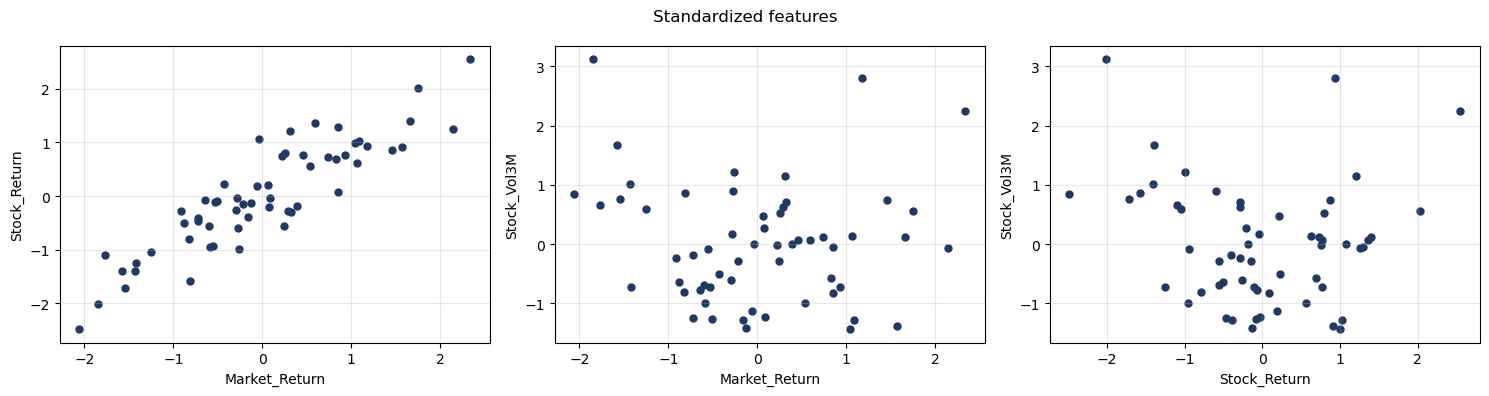

In [5]:
mu, s = X.mean(axis=0), X.std(axis=0)
Z = (X - mu) / s
print("means:", Z.mean(axis=0).round(6), " stds:", Z.std(axis=0).round(6))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for (a, b), axi in zip([(0, 1), (0, 2), (1, 2)], ax):
    axi.scatter(Z[:, a], Z[:, b], color="#1F3864", s=25)
    axi.set_xlabel(features[a]); axi.set_ylabel(features[b]); axi.grid(alpha=0.3)
plt.suptitle("Standardized features"); plt.tight_layout(); plt.show()

## Step 4 – The k-means optimization problem

We look for such clusters $S_1, ..S_k$  so that the variance (squared Euclidean distance) within each cluster is as small as possible. 

$$ J(\mathbf c_1,\dots,\mathbf c_k)=\sum_{i=1}^{n}\ \min_{j=1,\dots,k}\ \lVert \mathbf z_i-\mathbf c_j\rVert^2 . $$

where 
$$c_j=\frac{1}{|S_j|} \sum_{z \in S_j} z$$


In [12]:
def kmeans_objective(theta, Z, k):
    """Within-cluster sum of squares J for flattened centroids theta."""
    C = theta.reshape(k, -1)                                   # each centroid has d coordinates, so the total dimention is (k, d)
    D2 = ((Z[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)    # (n, k) squared distances. 
    return D2.min(axis=1).sum()

def assign(Z, C):
    """Index of the nearest centroid for every point."""
    D2 = ((Z[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)
    return D2.argmin(axis=1)

# sanity check: with k = 1 the optimal centroid is the mean, and J is the total sum of squares
print("J with centroid at the mean :", kmeans_objective(np.zeros(d), Z, 1).round(3))
print("J with centroid elsewhere   :", kmeans_objective(np.ones(d), Z, 1).round(3))

J with centroid at the mean : 174.0
J with centroid elsewhere   : 348.0


## Step 4.5 – Plot the objective function
Let us plot the objective. We'll fix some parametrs, to make 2D plot.

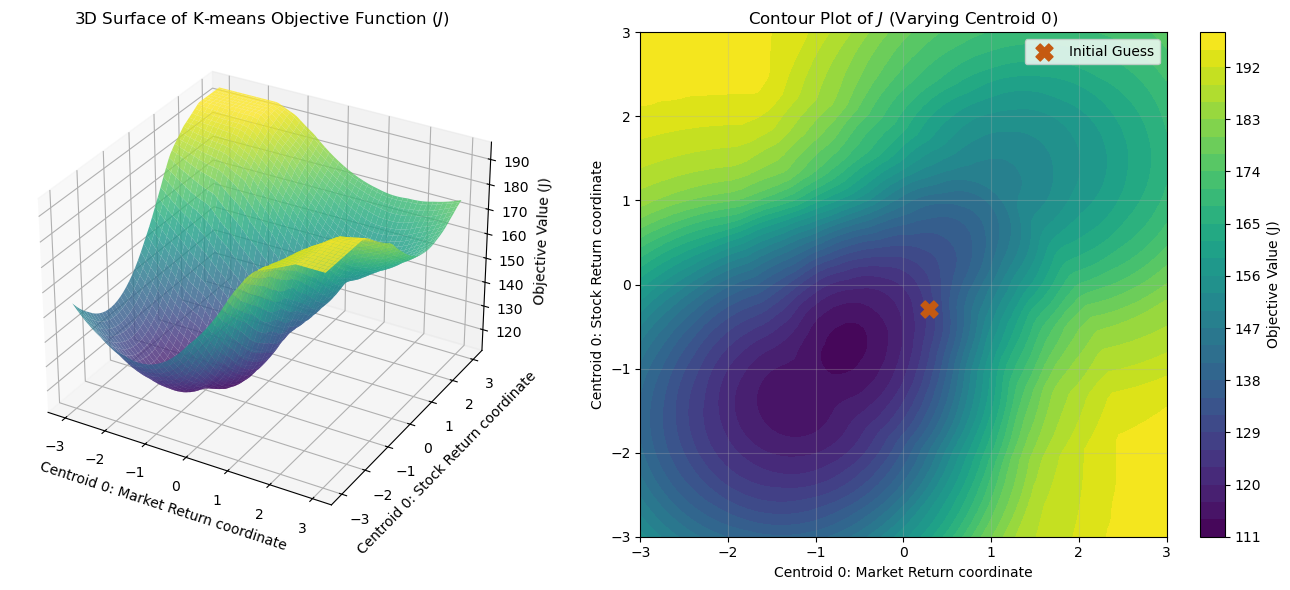

In [13]:
## --- Visualizing the K-means Objective Function Surface ---

# 1. Set up a baseline configuration for k=3
K = 3
rng = np.random.default_rng(1)
init_centroids = Z[rng.choice(len(Z), size=K, replace=False)] # shape (3, 3)

# 2. Define a grid to vary the first two coordinates of the first centroid
grid_range = np.linspace(-3.0, 3.0, 100)
x_val, y_val = np.meshgrid(grid_range, grid_range)
j_grid = np.zeros_like(x_val)

# 3. Compute the objective value J over the 2D grid
for i in range(x_val.shape[0]):
    for j in range(x_val.shape[1]):
        # Copy the baseline layout
        test_centroids = init_centroids.copy()
        # Vary the first centroid's x (Market_Return) and y (Stock_Return) coordinates
        test_centroids[0, 0] = x_val[i, j]
        test_centroids[0, 1] = y_val[i, j]
        
        # Flatten and compute objective
        j_grid[i, j] = kmeans_objective(test_centroids.ravel(), Z, K)

# 4. Create the 3D surface and 2D contour plots
fig = plt.figure(figsize=(14, 6))

# 3D Surface Plot
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(x_val, y_val, j_grid, cmap='viridis', alpha=0.8, edgecolor='none')
ax1.set_xlabel('Centroid 0: Market Return coordinate')
ax1.set_ylabel('Centroid 0: Stock Return coordinate')
ax1.set_zlabel('Objective Value (J)')
ax1.set_title('3D Surface of K-means Objective Function ($J$)')

# 2D Contour Plot (to clearly show local minima)
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(x_val, y_val, j_grid, levels=30, cmap='viridis')
fig.colorbar(contour, ax=ax2, label='Objective Value (J)')
ax2.scatter(init_centroids[0, 0], init_centroids[0, 1], color='#C55A11', marker='X', s=150, label='Initial Guess')
ax2.set_xlabel('Centroid 0: Market Return coordinate')
ax2.set_ylabel('Centroid 0: Stock Return coordinate')
ax2.set_title('Contour Plot of $J$ (Varying Centroid 0)')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


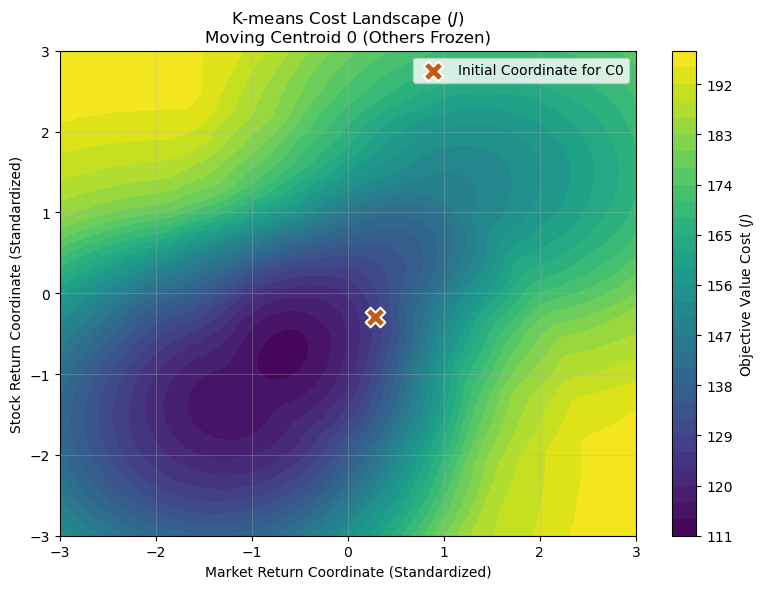

In [14]:
def plot_kmeans_landscape(Z, k, centroid_idx=0, grid_resolution=100, seed=1):
    """
    Plots a 2D contour map of the K-means objective function by varying 
    the first two coordinates (Market_Return and Stock_Return) of a chosen centroid index,
    while keeping the remaining centroids fixed.
    
    Parameters:
    -----------
    Z : ndarray
        Standardized feature matrix of shape (n_samples, n_features).
    k : int
        The number of clusters (typically 3).
    centroid_idx : int (0, 1, or 2)
        The index of the centroid to move across the grid space.
    grid_resolution : int
        The number of points along each grid axis (higher means smoother plots).
    seed : int
        Random seed used to match the baseline initializations in the notebook.
    """
    # 1. Regenerate the identical baseline initial centroids used in the notebook
    rng = np.random.default_rng(seed)
    init_centroids = Z[rng.choice(len(Z), size=k, replace=False)] # shape (k, d)
    
    # Validation check to prevent indexing errors
    if centroid_idx >= k or centroid_idx < 0:
        raise ValueError(f"Invalid centroid_idx={centroid_idx} for k={k}. Choose an index between 0 and {k-1}.")
        
    # 2. Build the coordinate evaluation grid from -3.0 to 3.0 standard deviations
    grid_range = np.linspace(-3.0, 3.0, grid_resolution)
    x_val, y_val = np.meshgrid(grid_range, grid_range)
    j_grid = np.zeros_like(x_val)
    
    # 3. Systematically evaluate the K-means objective cost function across the slice
    for i in range(x_val.shape[0]):
        for j in range(x_val.shape[1]):
            # Start with a clean copy of the frozen configuration
            test_centroids = init_centroids.copy()
            
            # Dynamically modify only the target centroid's first two coordinates:
            # Index [0] = Market_Return, Index [1] = Stock_Return
            test_centroids[centroid_idx, 0] = x_val[i, j]
            test_centroids[centroid_idx, 1] = y_val[i, j]
            
            # Flatten into a 1D vector and calculate total cost J
            j_grid[i, j] = kmeans_objective(test_centroids.ravel(), Z, k)
            
    # 4. Generate the Visualization
    plt.figure(figsize=(8, 6))
    
    # Select distinct color maps for different indices so they look distinct in your notebook
    cmaps = ['viridis', 'plasma', 'inferno']
    current_cmap = cmaps[centroid_idx % len(cmaps)]
    
    # Plot cost contours
    contour = plt.contourf(x_val, y_val, j_grid, levels=30, cmap=current_cmap)
    plt.colorbar(contour, label='Objective Value Cost ($J$)')
    
    # Mark where this specific centroid currently sits in the initial layout
    baseline_coord = init_centroids[centroid_idx]
    plt.scatter(baseline_coord[0], baseline_coord[1], 
                color='#1F3864' if centroid_idx != 0 else '#C55A11', 
                marker='X', s=200, edgecolor='white', linewidth=1.5,
                label=f'Initial Coordinate for C{centroid_idx}')
    
    plt.xlabel('Market Return Coordinate (Standardized)')
    plt.ylabel('Stock Return Coordinate (Standardized)')
    plt.title(f'K-means Cost Landscape ($J$)\nMoving Centroid {centroid_idx} (Others Frozen)')
    plt.legend(loc='upper right')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# --- Example Usage ---
# You can change the 'centroid_idx' argument to 0, 1, or 2 to see the different slices!

plot_kmeans_landscape(Z, k=3, centroid_idx=0)
#plot_kmeans_landscape(Z, k=3, centroid_idx=1)
#plot_kmeans_landscape(Z, k=3, centroid_idx=2)



## Step 5 – Minimize with Nelder–Mead

We choose $k=3$ for now. **Starting point:** pick $k$ random data points as initial centroids.

**Option `adaptive=True`:** the classical Nelder–Mead coefficients (reflection 1, expansion 2, contraction ½, shrink ½) are tuned for low dimension. With many parameters (here 9) the *adaptive* variant lets the coefficients depend on the dimension.

In [15]:
K = 3
rng = np.random.default_rng(1)

def run_nm(Z, k, rng):
    init = Z[rng.choice(len(Z), size=k, replace=False)]        # k random data points
    res = so.minimize(kmeans_objective, init.ravel(), args=(Z, k), method="Nelder-Mead",
                      options={"adaptive": True, "xatol": 1e-8, "fatol": 1e-10,
                               "maxiter": 20000, "maxfev": 20000})
    return res

res = run_nm(Z, K, rng)
C_nm = res.x.reshape(K, d)
labels = assign(Z, C_nm)
print(res.message)
print(f"J = {res.fun:.4f}   iterations = {res.nit}   function evaluations = {res.nfev}")
print("cluster sizes:", np.bincount(labels, minlength=K))
print("centroids (standardized units):\n", C_nm)

Optimization terminated successfully.
J = 66.2210   iterations = 1286   function evaluations = 2108
cluster sizes: [10 20 28]
centroids (standardized units):
 [[-1.2798 -1.4303  1.1628]
 [ 1.0212  1.101   0.1509]
 [-0.2724 -0.2756 -0.5231]]


## Step 6 – Local minima: why multi-start is needed

Because $J$ is non-convex, different starting points can end in different local minima. We run Nelder–Mead from 30 random starts and look at the distribution of the final $J$ values. The **global minimum** is the best value found over all starts – standard practice for k-means (scikit-learn does the same with `n_init`).

best J = 66.2210, median J = 66.2210, worst J = 91.1881
runs that reached the best value (within 1e-6): 18 of 30
median function evaluations per run: 1773


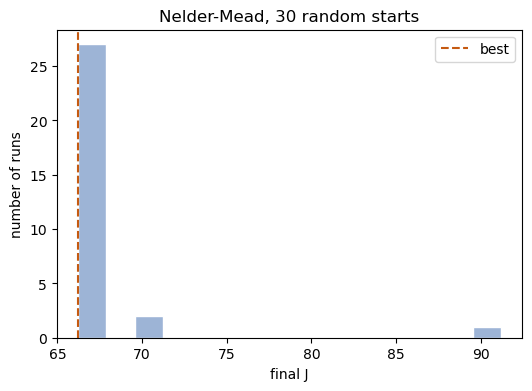

In [16]:
rng = np.random.default_rng(2)
runs = [run_nm(Z, K, rng) for _ in range(30)]
J_nm = np.array([r.fun for r in runs])
nfev_nm = np.array([r.nfev for r in runs])

print(f"best J = {J_nm.min():.4f}, median J = {np.median(J_nm):.4f}, worst J = {J_nm.max():.4f}")
print(f"runs that reached the best value (within 1e-6): {np.sum(J_nm < J_nm.min() + 1e-6)} of {len(J_nm)}")
print(f"median function evaluations per run: {int(np.median(nfev_nm))}")

plt.figure(figsize=(6, 4))
plt.hist(J_nm, bins=15, color="#9DB4D6", edgecolor="white")
plt.axvline(J_nm.min(), color="#C55A11", ls="--", label="best")
plt.xlabel("final J"); plt.ylabel("number of runs"); plt.title("Nelder-Mead, 30 random starts")
plt.legend(); plt.show()

best = runs[int(J_nm.argmin())]
C_nm = best.x.reshape(K, d)

## Step 7 – Lloyd's algorithm

The classical k-means algorithm alternates between two simple steps (it is a form of *coordinate descent*: first optimize the assignments with the centroids fixed, then the centroids with the assignments fixed):

1. **Assignment step:** assign each point to its nearest centroid.
2. **Update step:** move each centroid to the mean of its points.

The update step is exact: for a fixed cluster $S_j$, minimizing $\sum_{i\in S_j}\lVert\mathbf z_i-\mathbf c\rVert^2$ over $\mathbf c$ means setting the derivative $-2\sum_{i\in S_j}(\mathbf z_i-\mathbf c)$ to zero, which gives

$$ \mathbf c_j=\frac{1}{|S_j|}\sum_{i\in S_j}\mathbf z_i . $$

Both steps can only decrease $J$, and there are finitely many partitions, so the algorithm always converges – but, like Nelder–Mead, only to a *local* minimum.

In [18]:
def lloyd(Z, C0, max_iter=200):
    C = C0.copy()
    for it in range(1, max_iter + 1):
        lab = assign(Z, C)                                                  # assignment step
        C_new = np.array([Z[lab == j].mean(axis=0) if np.any(lab == j) else C[j]
                          for j in range(len(C))])                          # update step
        if np.allclose(C_new, C):
            break
        C = C_new
    return C, it

# same 30 random starting points for both methods (reproducible)
rng = np.random.default_rng(3)
starts = [Z[rng.choice(n, size=K, replace=False)] for _ in range(30)]

J_ll, it_ll, J_nm2, nfev_nm2 = [], [], [], []
for C0 in starts:
    C, it = lloyd(Z, C0)
    J_ll.append(kmeans_objective(C.ravel(), Z, K)); it_ll.append(it)
    r = so.minimize(kmeans_objective, C0.ravel(), args=(Z, K), method="Nelder-Mead",
                    options={"adaptive": True, "xatol": 1e-8, "fatol": 1e-10, "maxiter": 20000, "maxfev": 20000})
    J_nm2.append(r.fun); nfev_nm2.append(r.nfev)

J_ll, J_nm2 = np.array(J_ll), np.array(J_nm2)
pd.DataFrame({
    "best J":   [J_ll.min(), J_nm2.min()],
    "median J": [np.median(J_ll), np.median(J_nm2)],
    "worst J":  [J_ll.max(), J_nm2.max()],
    "median cost": [f"{int(np.median(it_ll))} iterations", f"{int(np.median(nfev_nm2))} f-evaluations"],
}, index=["Lloyd", "Nelder-Mead"]).round(4)

,best J,median J,worst J,median cost
Lloyd,66.221,67.0084,92.7054,5 iterations
Nelder-Mead,66.221,66.2444,85.6274,1808 f-evaluations


Note the difference in cost: one Lloyd iteration touches every point once, whereas Nelder–Mead evaluates $J$ hundreds or thousands of times. Lloyd uses the *structure* of the problem (the exact mean update); Nelder–Mead is generic and uses only function values. That is the usual trade-off between specialized and general-purpose optimizers. (In the runs above, Nelder–Mead ended in the best minimum a bit more often than Lloyd from the *same* starting centroids – its simplex can step across the ridges where Lloyd's hard assignments get stuck – but at hundreds of times the cost.)

## Step 8 – Choosing the number of clusters $k$

$J$ always decreases as $k$ grows (with $k=n$ it is zero), so we cannot simply minimize it over $k$. Two common tools:

**Elbow method.** Plot the best $J$ against $k$ and look for the "elbow", where adding clusters stops paying off.

**Silhouette score.** For point $i$ let $a_i$ be its mean distance to the other points in its own cluster and $b_i$ the smallest mean distance to the points of any other cluster. Then

$$ s_i=\frac{b_i-a_i}{\max(a_i,b_i)}\in[-1,1],\qquad \text{silhouette}=\frac1n\sum_i s_i . $$

Values near 1 mean compact, well-separated clusters; values near 0 mean overlapping clusters, values below 0 mean the point could be assigned to a wrong cluster

For every $k$ we run Nelder–Mead from 10 random starts and keep the best result. Watch the cost columns: the number of parameters is $k\cdot d$.

,parameters (k*d),best J,silhouette,total f-evals (10 starts)
k,,,,
1,3,174.000,NaN,2861
2,6,101.443,0.375,10476
3,9,66.221,0.379,22244
4,12,50.503,0.353,32223
5,15,40.642,0.361,48953
6,18,32.202,0.376,68221


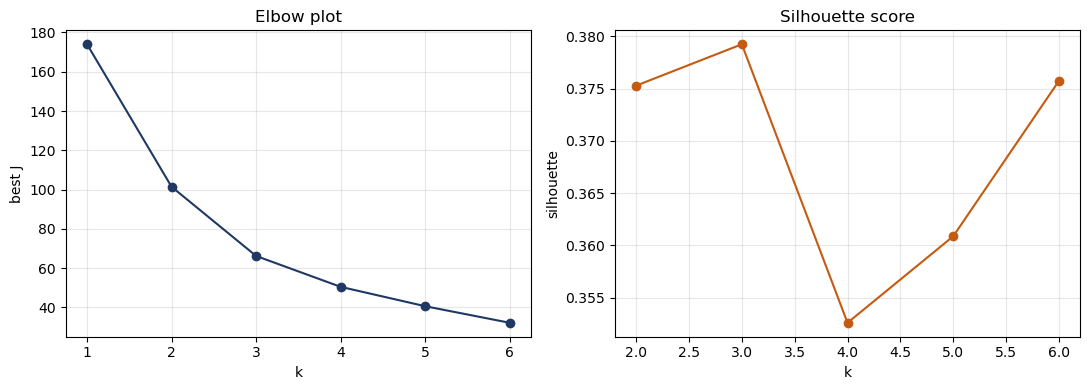

k with the highest silhouette: 3


In [20]:
def silhouette(Z, labels):
    D = np.sqrt(((Z[:, None, :] - Z[None, :, :]) ** 2).sum(axis=2))   # pairwise distances
    ks = np.unique(labels)
    scores = []
    for i in range(len(Z)):
        own = labels == labels[i]
        if own.sum() == 1:
            scores.append(0.0); continue
        a = D[i, own].sum() / (own.sum() - 1)
        b = min(D[i, labels == c].mean() for c in ks if c != labels[i])
        scores.append((b - a) / max(a, b))
    return np.mean(scores)

rng = np.random.default_rng(4)
rows, best_models = [], {}
for k in range(1, 7):
    results = [run_nm(Z, k, rng) for _ in range(10)]
    b = min(results, key=lambda r: r.fun)
    Ck = b.x.reshape(k, d); lab = assign(Z, Ck)
    best_models[k] = (Ck, lab)
    rows.append({"k": k, "parameters (k*d)": k * d, "best J": b.fun,
                 "silhouette": silhouette(Z, lab) if k > 1 and len(np.unique(lab)) > 1 else np.nan,
                 "total f-evals (10 starts)": sum(r.nfev for r in results)})
scan = pd.DataFrame(rows).set_index("k")
display(scan.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(scan.index, scan["best J"], "o-", color="#1F3864"); ax[0].set_title("Elbow plot")
ax[0].set_xlabel("k"); ax[0].set_ylabel("best J")
ax[1].plot(scan.index[1:], scan["silhouette"][1:], "o-", color="#C55A11"); ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k"); ax[1].set_ylabel("silhouette")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("k with the highest silhouette:", int(scan["silhouette"].idxmax()))

**Reading the plots.** A pronounced elbow and a silhouette close to 1 would indicate real cluster structure. The data in this notebook are **simulated with independent, normally distributed returns** – there are no hidden regimes. k-means imply cuts a continuous cloud of points into pieces (e.g. "down months", "average months", "up months"). With real data a stronger structure can appear, for example a separate cluster of high-volatility crash months.

## Step 9 – Final clustering and interpretation

Choose the number of clusters (default $k=3$; change `K_FINAL` to the value you prefer after looking at Step 8). Clusters are sorted by their mean market return so the labels are reproducible, and centroids are transformed back to original units with $x = z\cdot s+\mu$.

In [21]:
K_FINAL = 3
C_z, lab = best_models[K_FINAL]

order = np.argsort(C_z[:, 0])                      # sort clusters by market-return centroid
remap = {old: new for new, old in enumerate(order)}
lab = np.array([remap[l] for l in lab]); C_z = C_z[order]
C_orig = C_z * s + mu                              # back to original units

df["Cluster"] = lab
profile = pd.DataFrame(C_orig, columns=features)
profile.insert(0, "months", np.bincount(lab, minlength=K_FINAL))
profile.index.name = "cluster"
print("J =", round(kmeans_objective(C_z.ravel(), Z, K_FINAL), 3),
      "  silhouette =", round(silhouette(Z, lab), 3))
profile.round(4)

J = 66.221   silhouette = 0.379


,months,Market_Return,Stock_Return,Stock_Vol3M
cluster,,,,
0,10,-0.0526,-0.0865,0.0968
1,28,-0.0075,-0.0103,0.0394
2,20,0.0504,0.0806,0.0624


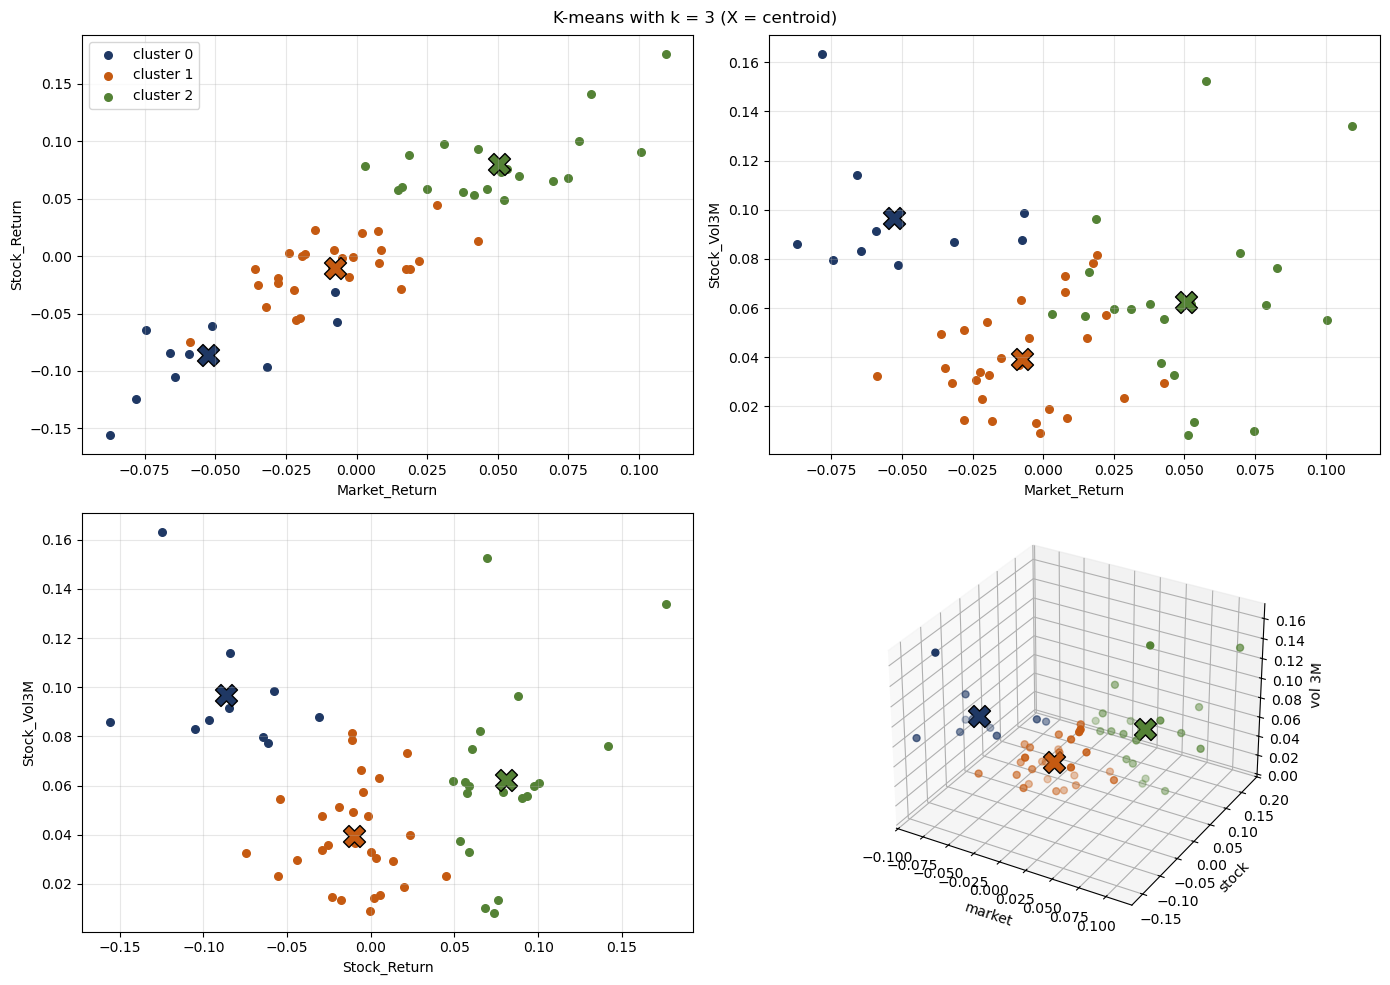

In [22]:
fig = plt.figure(figsize=(14, 10))
pairs = [(0, 1), (0, 2), (1, 2)]
for p, (a, b) in enumerate(pairs):
    ax = fig.add_subplot(2, 2, p + 1)
    for j in range(K_FINAL):
        m = lab == j
        ax.scatter(X[m, a], X[m, b], color=COLORS[j], s=30, label=f"cluster {j}")
        ax.scatter(C_orig[j, a], C_orig[j, b], color=COLORS[j], marker="X", s=250, edgecolor="black")
    ax.set_xlabel(features[a]); ax.set_ylabel(features[b]); ax.grid(alpha=0.3)
    if p == 0: ax.legend()
ax3 = fig.add_subplot(2, 2, 4, projection="3d")
for j in range(K_FINAL):
    m = lab == j
    ax3.scatter(X[m, 0], X[m, 1], X[m, 2], color=COLORS[j], s=25)
    ax3.scatter(*C_orig[j], color=COLORS[j], marker="X", s=250, edgecolor="black")
ax3.set_xlabel("market"); ax3.set_ylabel("stock"); ax3.set_zlabel("vol 3M")
plt.suptitle(f"K-means with k = {K_FINAL} (X = centroid)"); plt.tight_layout(); plt.show()

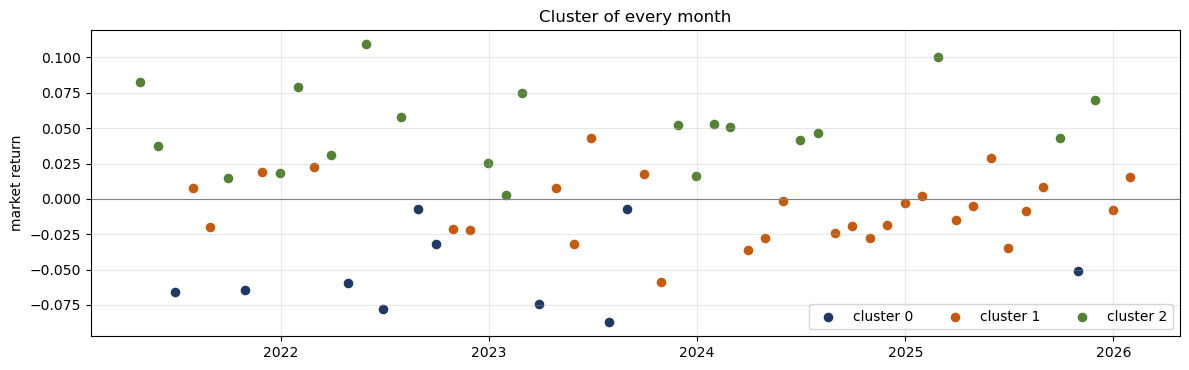

In [23]:
fig, ax = plt.subplots(figsize=(12, 3.8))
for j in range(K_FINAL):
    m = df["Cluster"] == j
    ax.scatter(df.loc[m, "Date"], df.loc[m, "Market_Return"], color=COLORS[j], s=35, label=f"cluster {j}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("market return"); ax.set_title("Cluster of every month"); ax.legend(ncol=K_FINAL); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## TODO


1. Replace the volatility feature by 3-month momentum, $P_t/P_{t-3}-1$, and compare the clusters.
2. Run Lloyd with *k-means++* initialization (choose each new initial centroid with probability proportional to its squared distance to the nearest existing one) and see how often it finds the best $J$.
3. Use real prices (cell below)

## Optional – use real data

Same cell as in the regression notebook: it downloads real month-end prices with `yfinance` (`pip install yfinance`, internet needed) and writes the same Excel layout. Set `USE_REAL_DATA = True`, run it, then re-run the notebook from Step 1.

In [24]:
USE_REAL_DATA = True

if USE_REAL_DATA:
    import yfinance as yf
    raw = yf.download(["^GSPC", "AAPL"], start="2019-12-31", end="2025-01-01",
                      interval="1mo", auto_adjust=True)["Close"]
    out = raw.rename(columns={"^GSPC": "Market_Index", "AAPL": "Stock_Price"}).dropna()
    out.index.name = "Date"
    out[["Market_Index", "Stock_Price"]].reset_index().to_excel(
        "stock_market_prices1.xlsx", sheet_name="Prices", index=False)
    print("saved", len(out), "rows")

[*********************100%***********************]  2 of 2 completed

saved 60 rows
